# Chapter 1 — The SLAM problem: a linear SLAM you can solve in one line

Companion notebook to **Chapter 1** of the course notes (`course/main.pdf`).
Everything here is the one-dimensional problem of *Example 1.11*:

$$x_k = x_{k-1} + u_k + w_k,\quad w_k\sim\mathcal N(0,\sigma_u^2),\qquad
z_{kj} = m_j - x_k + v_{kj},\quad v_{kj}\sim\mathcal N(0,\sigma_z^2),$$

with a prior $x_0\sim\mathcal N(0,\sigma_0^2)$. Because every model is linear and Gaussian, the MAP estimate
(Proposition 1.5) is the solution of **one** linear least-squares problem, and its covariance is exactly $(A^\top A)^{-1}$.

The functions used here live in `examples/ch01_linear_slam.py`; the script regenerates the figures of the PDF.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent            # the code/ directory
sys.path[:0] = [str(ROOT), str(ROOT / "examples")]

import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

from ch01_linear_slam import simulate, build_system, marginalise, filtered_sigmas
# after the imports: the example scripts select the Agg backend
%matplotlib inline

## 1. The scene

The robot drives from $0$ to $10$ m along a row of 11 landmarks spaced 1 m apart, in steps of 0.5 m, and comes back.
It sees a landmark only when it is within 0.75 m.

41 poses, 11 landmarks, 61 observations


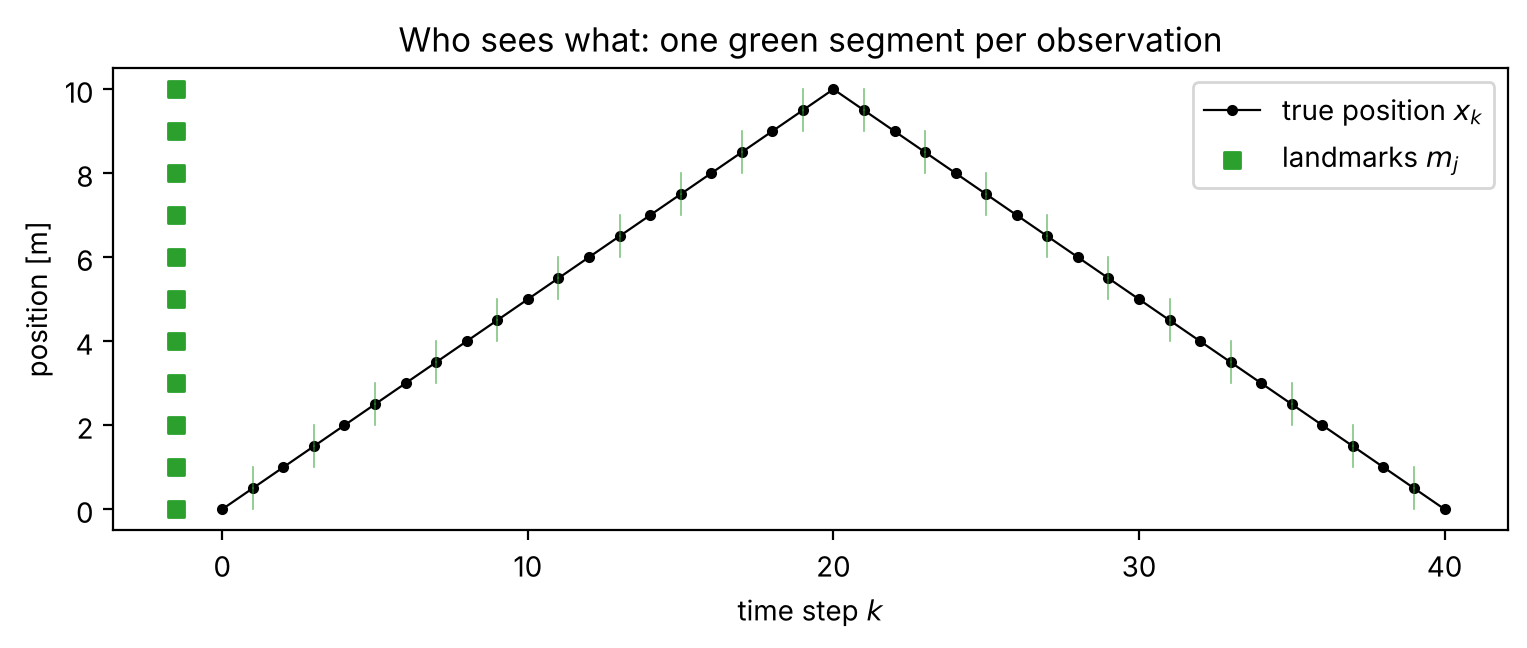

In [2]:
pb = simulate(seed=0)
K1, N = len(pb.x_true), len(pb.m_true)
print(f"{K1} poses, {N} landmarks, {len(pb.obs)} observations")

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(np.arange(K1), pb.x_true, "k.-", lw=0.8, label="true position $x_k$")
for k, j, _ in pb.obs:
    ax.plot([k, k], [pb.x_true[k], pb.m_true[j]], color="tab:green", lw=0.6, alpha=0.6)
ax.scatter(np.full(N, -1.5), pb.m_true, marker="s", color="tab:green", label="landmarks $m_j$")
ax.set_xlabel("time step $k$"); ax.set_ylabel("position [m]"); ax.legend(loc="upper right")
ax.set_title("Who sees what: one green segment per observation");

## 2. The whitened linear system

Each factor of the graph (prior, odometry, observation) contributes one row of $A$, already divided by its standard
deviation (*whitening*, Section 1.3). The unknowns are ordered $\boldsymbol\theta = (x_0,\dots,x_K,m_1,\dots,m_N)$.

In [3]:
A, b = build_system(pb)
print("A:", A.shape, " b:", b.shape)
print("first rows of A (prior, then odometry):")
print(A[:3, :5])

A: (102, 52)  b: (102,)
first rows of A (prior, then odometry):
[[100.   0.   0.   0.   0.]
 [-10.  10.   0.   0.   0.]
 [  0. -10.  10.   0.   0.]]


## 3. MAP estimate and its covariance

Minimising $\tfrac12\|A\boldsymbol\theta-\mathbf b\|^2$ means solving the normal equations
$H\boldsymbol\theta = A^\top\mathbf b$ with $H = A^\top A$.

In [4]:
H = A.T @ A
theta = np.linalg.solve(H, A.T @ b)
cov = np.linalg.inv(H)
x_hat, m_hat = theta[:K1], theta[K1:]

print("RMS pose error     :", np.sqrt(np.mean((x_hat - pb.x_true) ** 2)))
print("RMS landmark error :", np.sqrt(np.mean((m_hat - pb.m_true) ** 2)))
print("landmark estimates :", m_hat.round(3))

RMS pose error     : 0.2441378073927342
RMS landmark error : 0.24725043124718604
landmark estimates : [-0.01   0.971  1.972  2.981  3.859  4.836  5.786  6.796  7.642  8.599
  9.503]


## 4. The factor graph *is* the sparsity pattern (Proposition 1.7)

$H_{ij}\neq 0$ only if variables $i$ and $j$ share a factor. Below: odometry gives the tri-diagonal pose block, observations
give the two "wings" linking each landmark to the poses that saw it — once on the way out, once on the way back.

density of H: 9.4%


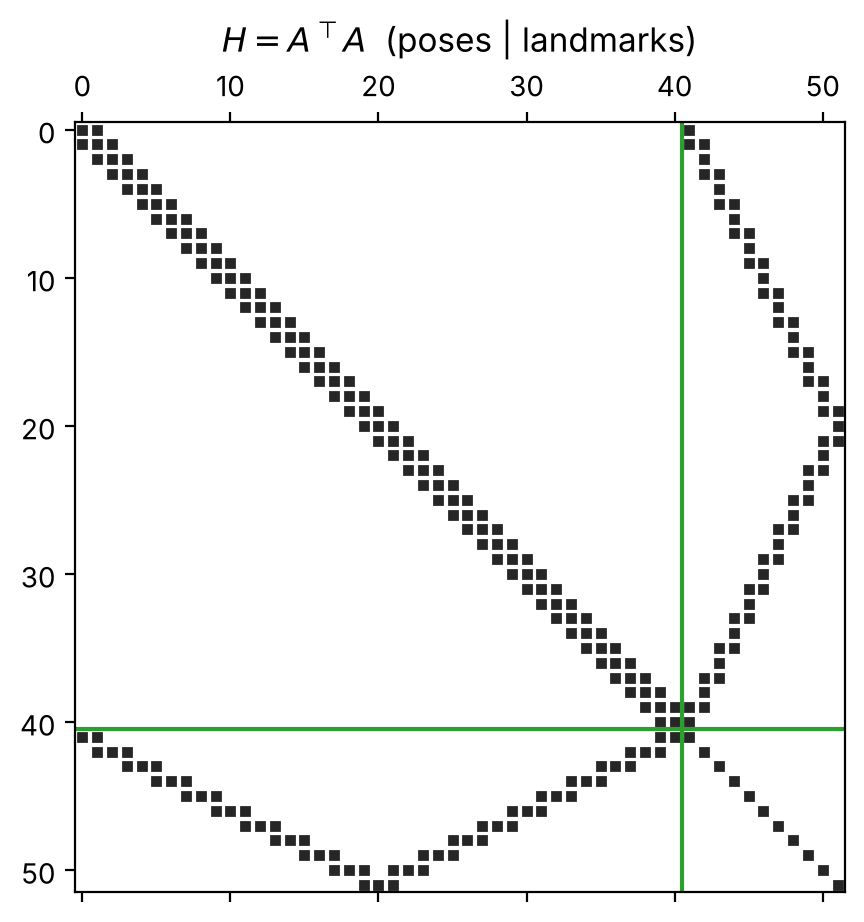

In [5]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.spy(np.abs(H) > 1e-12, markersize=3, color="0.15")
ax.axhline(K1 - 0.5, color="tab:green"); ax.axvline(K1 - 0.5, color="tab:green")
ax.set_title("$H = A^\\top A$  (poses | landmarks)")
print(f"density of H: {np.mean(np.abs(H) > 1e-12):.1%}")

## 5. Marginalisation creates fill-in (Lemma 1.8, Proposition 1.9)

### 5a. Forget every pose
This is what a filter ends up carrying: the information of the landmarks alone. It is dense.

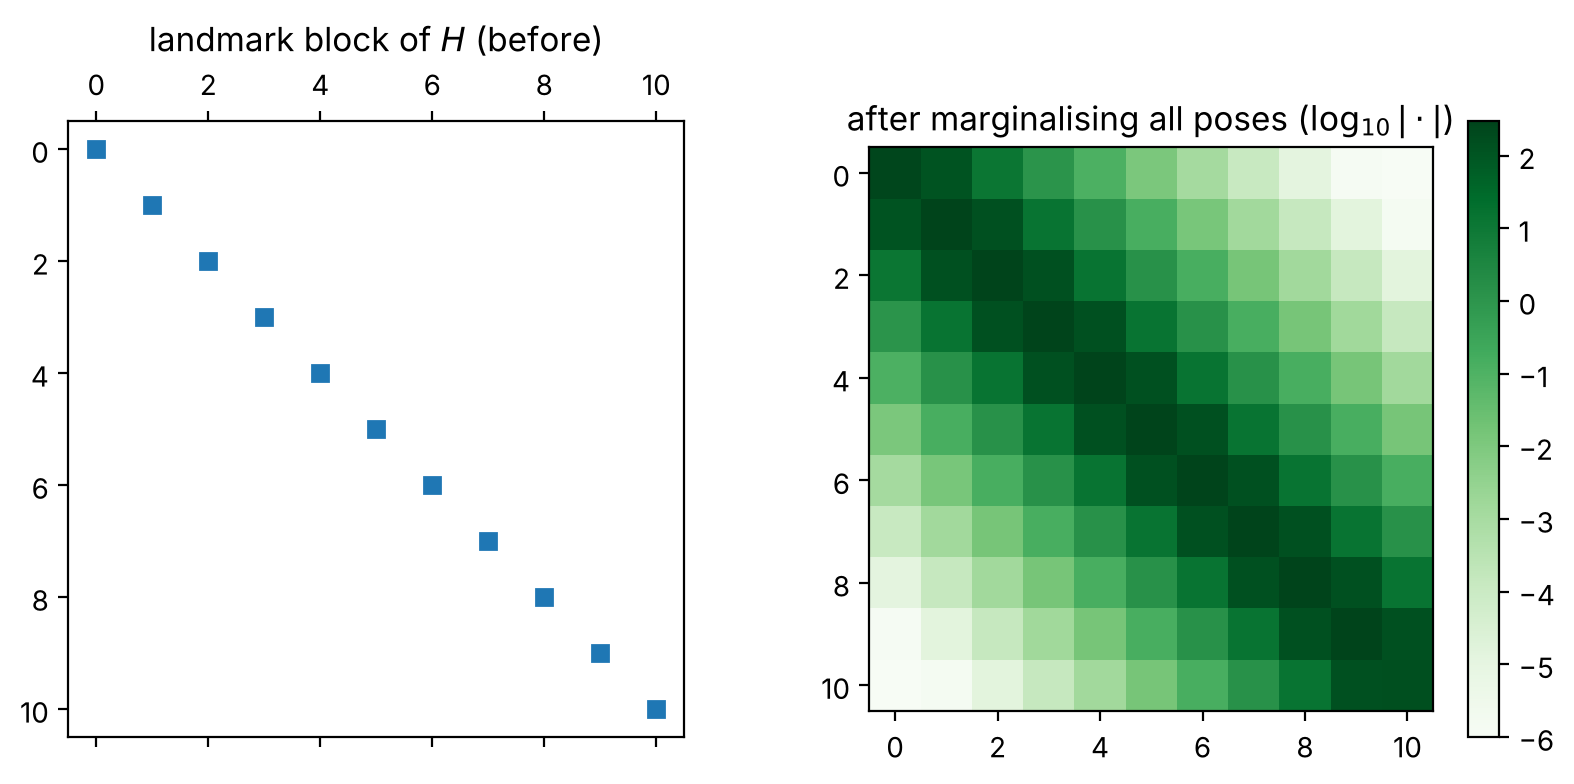

In [6]:
L_mm = marginalise(H, np.arange(K1, K1 + N))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].spy(np.abs(H[K1:, K1:]) > 1e-12, markersize=6); ax[0].set_title("landmark block of $H$ (before)")
im = ax[1].imshow(np.log10(np.abs(L_mm) + 1e-12), cmap="Greens", vmin=-6)
ax[1].set_title("after marginalising all poses ($\\log_{10}|\\cdot|$)"); fig.colorbar(im, ax=ax[1]);

### 5b. Forget a single pose (Exercise 1.3)

Marginalise only $x_k$ and list which pairs of variables become newly connected. The prediction of Exercise 1.3 is:
every pair among $\{x_{k-1}, x_{k+1}\}\cup L_k$, where $L_k$ are the landmarks seen at time $k$.
In this scene the neighbouring poses already see the same landmark, so only the odometry pair $x_{k-1}$–$x_{k+1}$ is new;
the point is that *all* pairs of the clique are connected afterwards.

In [7]:
k = 6
keep = np.setdiff1d(np.arange(K1 + N), [k])
Hk = marginalise(H, keep)
before = np.abs(H[np.ix_(keep, keep)]) > 1e-12
after = np.abs(Hk) > 1e-12

names = [f"x{i}" for i in range(K1)] + [f"m{j}" for j in range(N)]
idx = {n: i for i, n in enumerate(names)}
L_k = [f"m{j}" for kk, j, _ in pb.obs if kk == k]
clique = [f"x{k-1}", f"x{k+1}"] + L_k
print("landmarks seen at time", k, ":", L_k)
print("predicted clique:", clique)

H_keep = H[np.ix_(keep, keep)]
pos = {n: list(keep).index(idx[n]) for n in clique}
for i, a in enumerate(clique):
    for c in clique[i + 1:]:
        was = abs(H_keep[pos[a], pos[c]]) > 1e-12
        now = abs(Hk[pos[a], pos[c]]) > 1e-12
        print(f"  {a}-{c}: before {'yes' if was else 'no '}  after {'yes' if now else 'no'}")

landmarks seen at time 6 : ['m3']
predicted clique: ['x5', 'x7', 'm3']
  x5-x7: before no   after yes
  x5-m3: before yes  after yes
  x7-m3: before yes  after yes


## 6. Filtering versus smoothing

The *filtered* standard deviation of $x_k$ uses only the data up to time $k$ (what a Kalman filter reports);
the *smoothed* one uses all the data (diagonal of $H^{-1}$). Watch the filtered band shrink on the way back —
a one-dimensional loop closure.

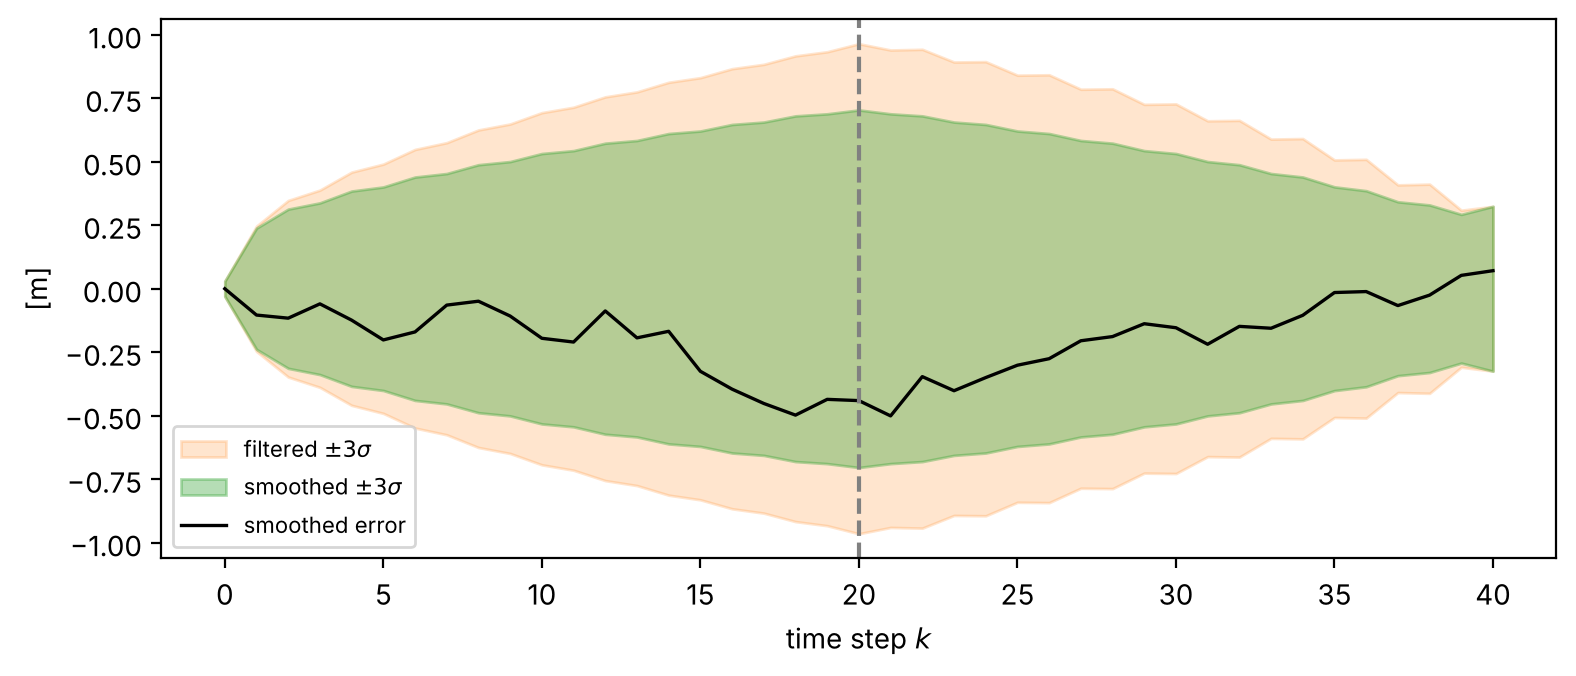

In [8]:
sig_s = np.sqrt(np.diag(cov))[:K1]
sig_f = filtered_sigmas(pb)
k = np.arange(K1)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.fill_between(k, -3 * sig_f, 3 * sig_f, color="tab:orange", alpha=0.2, label="filtered $\\pm3\\sigma$")
ax.fill_between(k, -3 * sig_s, 3 * sig_s, color="tab:green", alpha=0.35, label="smoothed $\\pm3\\sigma$")
ax.plot(k, x_hat - pb.x_true, "k", lw=1.2, label="smoothed error")
ax.axvline((K1 - 1) / 2, color="0.5", ls="--")
ax.set_xlabel("time step $k$"); ax.set_ylabel("[m]"); ax.legend(loc="lower left", fontsize=8);

## 7. Gauge freedom (Proposition 1.10, Exercise 1.2)

Drop the prior on $x_0$: every remaining row of $A$ sums to zero, so translating the whole world changes nothing and
$\mathbf 1$ spans the null space of $H$.

In [9]:
A0, _ = build_system(pb, with_prior=False)
H0 = A0.T @ A0
print("three smallest eigenvalues:", np.linalg.eigvalsh(H0)[:3])
print("|H0 @ 1| =", np.linalg.norm(H0 @ np.ones(K1 + N)))

three smallest eigenvalues: [-0.      3.6401 14.4406]
|H0 @ 1| = 0.0


## 8. Try it yourself

* Increase `sensor_range` in `simulate` to 1.5 m. What happens to the gap between filtered and smoothed bands, and why?
* Set `sigma_u` to 0.5 (wheels slipping on wet grass). Which variables does the estimate lean on now?
* Remove all observations made on the way back. Is there still a loop closure?